# Hands-on 2: Membaca Data Sensor Dummy CSV dan Membuat Visualisasi Pertama

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* oleh Onno W. Purbo (Halaman 54–64).

### Tujuan Hands-on:
1. Membaca data time-series sensor IoT dalam format CSV menggunakan pandas.
2. Mengenali elemen penting data IoT: timestamp, device_id, serta metrik pengukuran (suhu, kelembaban, CO2, daya).
3. Melakukan transformasi timestamp menjadi format datetime dan menjadikannya index data.
4. Membuat visualisasi plot deret waktu dan visualisasi korelasi antar-variabel sensor.
5. Mengekspor data olahan ke direktori `data/processed/`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

print("[INFO] Pustaka analitik berhasil diimpor.")


[INFO] Pustaka analitik berhasil diimpor.


### 1. Membaca Dataset Dummy CSV
Dataset `room_sensor_dummy.csv` mensimulasikan monitoring kondisi ruangan (suhu, kelembaban, CO2, daya) per 10 menit.


In [2]:
data_path = Path("../data/raw/room_sensor_dummy.csv")
if not data_path.exists():
    data_path = Path("data/raw/room_sensor_dummy.csv")

df = pd.read_csv(data_path)
df.head(10)


,timestamp,device_id,temperature_c,humidity_pct,co2_ppm,power_watt
0,2026-01-01 08:00:00,room01,24.5,58,520,110
1,2026-01-01 08:10:00,room01,24.7,57,525,112
2,2026-01-01 08:20:00,room01,25.1,56,540,115
3,2026-01-01 08:30:00,room01,25.6,55,560,118
4,2026-01-01 08:40:00,room01,26.0,54,590,121
5,2026-01-01 08:50:00,room01,26.4,53,610,124
6,2026-01-01 09:00:00,room01,26.9,52,640,128
7,2026-01-01 09:10:00,room01,27.3,51,670,132
8,2026-01-01 09:20:00,room01,27.8,50,700,136
9,2026-01-01 09:30:00,room01,28.2,49,730,141


### 2. Konversi Timestamp Menjadi Indeks Waktu
Mengubah kolom string `timestamp` menjadi tipe data `datetime64` dan menetapkannya sebagai index dataframe.


In [3]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp")
df.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 20 entries, 2026-01-01 08:00:00 to 2026-01-01 11:10:00
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   device_id      20 non-null     str    
 1   temperature_c  20 non-null     float64
 2   humidity_pct   20 non-null     int64  
 3   co2_ppm        20 non-null     int64  
 4   power_watt     20 non-null     int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 960.0 bytes


### 3. Ringkasan Statistik Numerik

In [4]:
df.describe()

,temperature_c,humidity_pct,co2_ppm,power_watt
count,20.000000,20.000000,20.000000,20.000000
mean,27.330000,50.950000,685.000000,133.600000
std,1.490355,3.634267,99.511967,13.421899
min,24.500000,46.000000,520.000000,110.000000
25%,26.300000,48.000000,605.000000,123.250000
50%,27.700000,50.500000,700.000000,135.000000
75%,28.550000,53.250000,765.000000,145.500000
max,29.100000,58.000000,815.000000,151.000000


### 4. Visualisasi Deret Waktu Suhu Ruangan

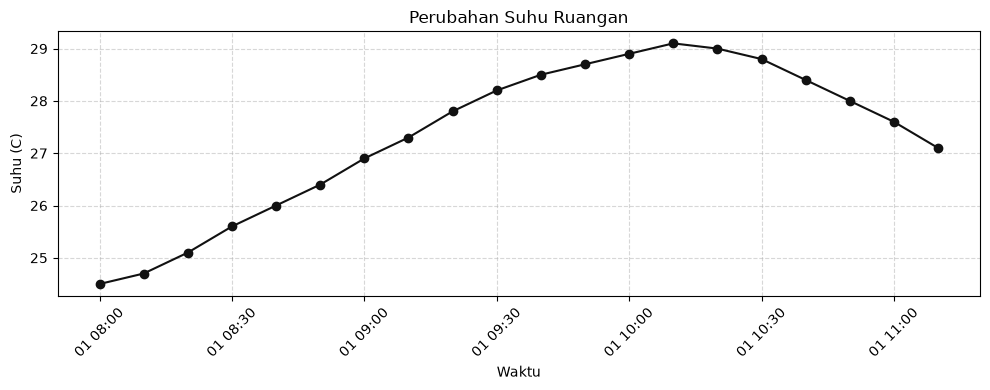

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["temperature_c"], marker="o", color="#111111", linewidth=1.5)
plt.title("Perubahan Suhu Ruangan")
plt.xlabel("Waktu")
plt.ylabel("Suhu (C)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 5. Visualisasi Multi-Variabel (Suhu, Kelembaban, CO2)

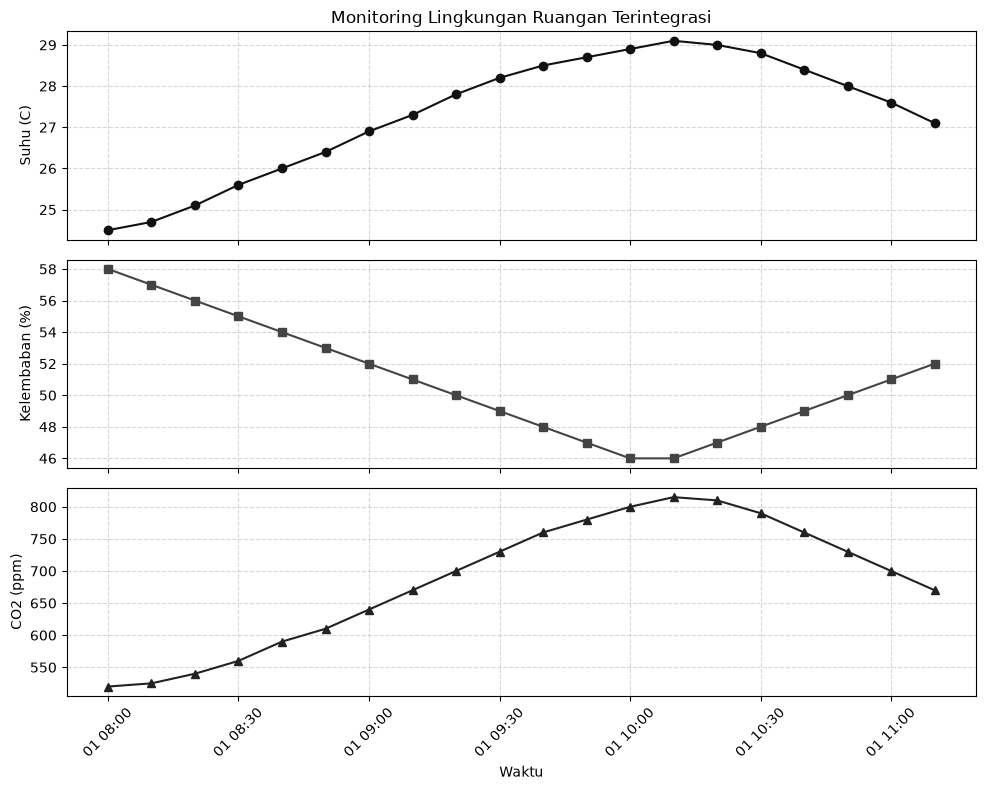

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(df.index, df["temperature_c"], marker="o", color="#111111")
axes[0].set_ylabel("Suhu (C)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].set_title("Monitoring Lingkungan Ruangan Terintegrasi")

axes[1].plot(df.index, df["humidity_pct"], marker="s", color="#444444")
axes[1].set_ylabel("Kelembaban (%)")
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].plot(df.index, df["co2_ppm"], marker="^", color="#222222")
axes[2].set_ylabel("CO2 (ppm)")
axes[2].set_xlabel("Waktu")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 6. Eksplorasi Hubungan Antar-Variabel (Suhu vs CO2)

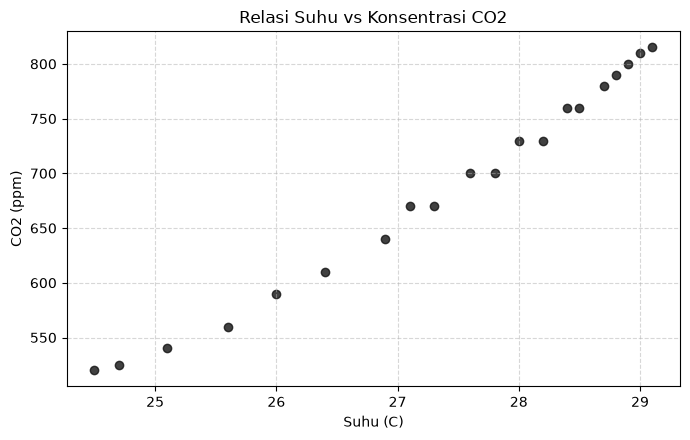

In [7]:
plt.figure(figsize=(7, 4.5))
plt.scatter(df["temperature_c"], df["co2_ppm"], color="#111111", alpha=0.8)
plt.title("Relasi Suhu vs Konsentrasi CO2")
plt.xlabel("Suhu (C)")
plt.ylabel("CO2 (ppm)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 7. Ekspor Data Bersih ke `data/processed/`

In [8]:
output_clean = Path("../data/processed/room_sensor_clean.csv")
if not output_clean.parent.exists():
    output_clean = Path("data/processed/room_sensor_clean.csv")

output_clean.parent.mkdir(parents=True, exist_ok=True)
df.reset_index().to_csv(output_clean, index=False)
print(f"[SUKSES] Data bersih tersimpan ke: {output_clean}")


[SUKSES] Data bersih tersimpan ke: data/processed/room_sensor_clean.csv
